majority baseline: vilifying_opponents
                      precision  recall  f1-score
nothing                   0.000   0.000     0.000
personality_cult          0.000   0.000     0.000
vilifying_eu              0.000   0.000     0.000
vilifying_neighbours      0.000   0.000     0.000
vilifying_opponents       0.538   1.000     0.700
accuracy                  0.538   0.538     0.538
macro avg                 0.108   0.200     0.140
weighted avg              0.289   0.538     0.376
                      precision  recall  f1-score
nothing                   0.400   0.636     0.491
personality_cult          0.500   0.286     0.364
vilifying_eu              0.000   0.000     0.000
vilifying_neighbours      0.200   0.200     0.200
vilifying_opponents       0.712   0.732     0.722
accuracy                  0.545   0.545     0.545
macro avg                 0.362   0.371     0.355
weighted avg              0.507   0.545     0.520


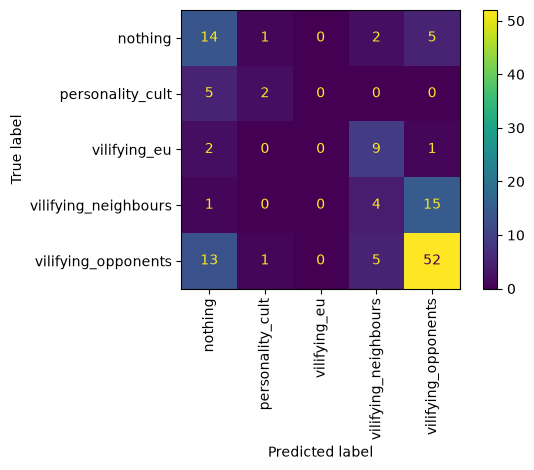

In [1]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

sys.path.insert(0, str(Path.cwd()))

from data import load_data, load_stopwords, make_groups
from evaluation import baseline_predictions, evaluate, split_data
from model import build_model, top_features

data = load_data("../data/processed/headlines.csv")
data["group"] = make_groups(data)
labels = sorted(data["label"].unique())
train_indices, test_indices = split_data(data)
train = data.iloc[train_indices]
test = data.iloc[test_indices]

majority_label, baseline = baseline_predictions(train["label"], len(test))
print(f"majority baseline: {majority_label}")
print(pd.DataFrame(evaluate(test["label"], baseline, labels)["report"]).T[["precision", "recall", "f1-score"]].round(3))

data["label"].value_counts()

classifier = make_pipeline(
	TfidfVectorizer(stop_words=load_stopwords()),
	DecisionTreeClassifier(random_state=42),
)
classifier.fit(train["headline"], train["label"])
predictions = classifier.predict(test["headline"])

print(
	pd.DataFrame(evaluate(test["label"], predictions, labels)["report"])
	.T[["precision", "recall", "f1-score"]]
	.round(3)
)
ConfusionMatrixDisplay.from_predictions(
	test["label"], predictions, labels=labels, xticks_rotation="vertical"
)
plt.tight_layout()
plt.show()



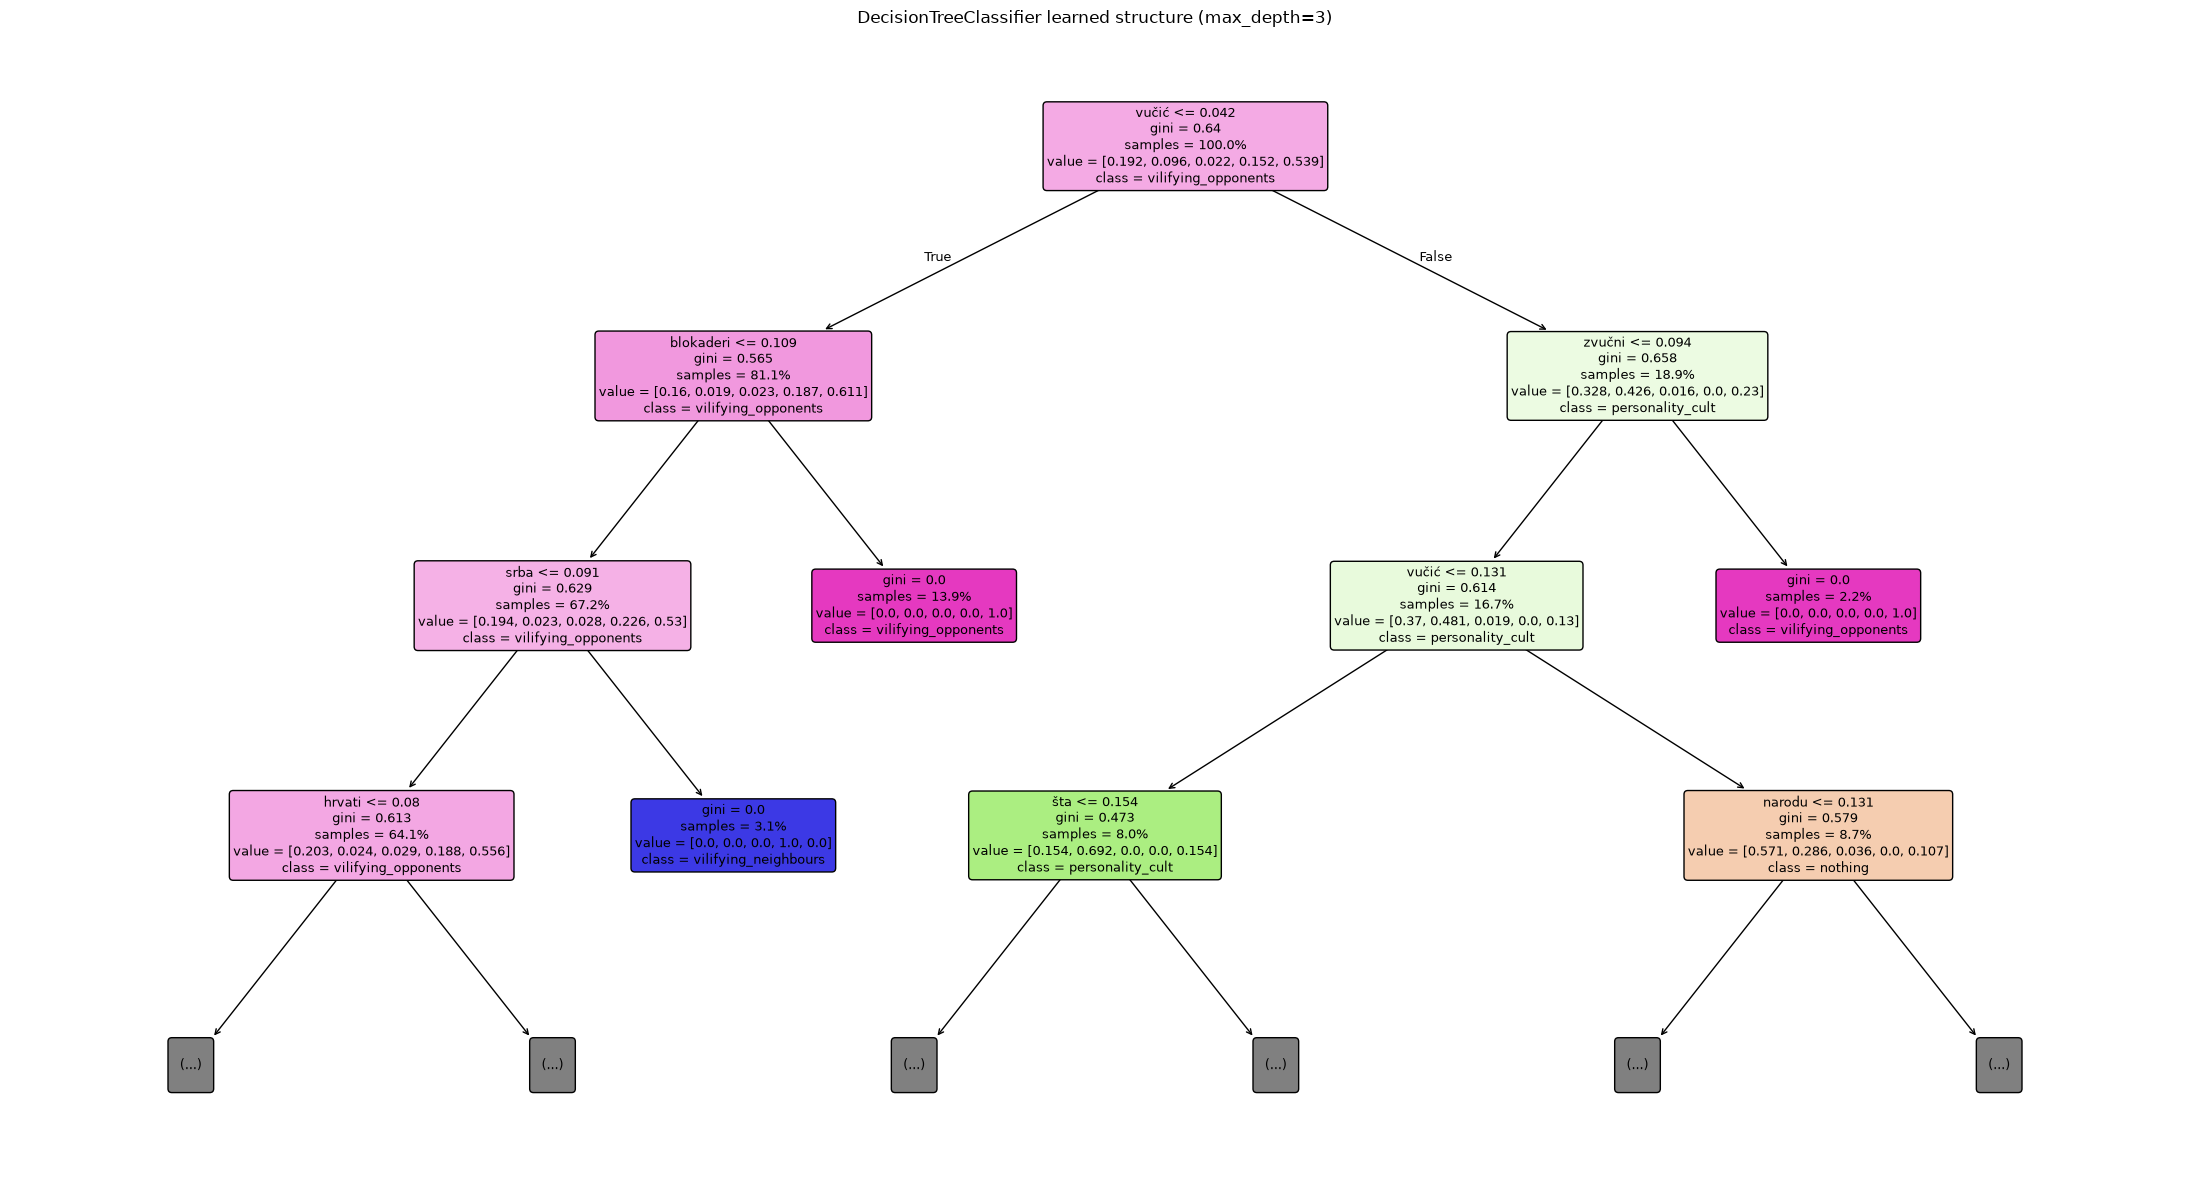

Tree nodes: 149
Tree depth: 41
|--- vučić <= 0.04
|   |--- blokaderi <= 0.11
|   |   |--- srba <= 0.09
|   |   |   |--- hrvati <= 0.08
|   |   |   |   |--- velike <= 0.12
|   |   |   |   |   |--- hrvatska <= 0.12
|   |   |   |   |   |   |--- macut <= 0.12
|   |   |   |   |   |   |   |--- mali <= 0.20
|   |   |   |   |   |   |   |   |--- srpske <= 0.09
|   |   |   |   |   |   |   |   |   |--- krade <= 0.17
|   |   |   |   |   |   |   |   |   |   |--- narod <= 0.21
|   |   |   |   |   |   |   |   |   |   |   |--- truncated branch of depth 31
|   |   |   |   |   |   |   |   |   |   |--- narod >  0.21
|   |   |   |   |   |   |   |   |   |   |   |--- weights: [3.00, 0.00, 0.00, 0.00, 0.00] class: nothing
|   |   |   |   |   |   |   |   |   |--- krade >  0.17
|   |   |   |   |   |   |   |   |   |   |--- weights: [0.00, 0.00, 0.00, 3.00, 0.00] class: vilifying_neighbours
|   |   |   |   |   |   |   |   |--- srpske >  0.09
|   |   |   |   |   |   |   |   |   |--- gazivodama <= 0.15
|   |   |  

In [2]:
from sklearn.tree import plot_tree, export_text

tree = classifier.named_steps["decisiontreeclassifier"]
vectorizer = classifier.named_steps["tfidfvectorizer"]
feature_names = vectorizer.get_feature_names_out()

# Plot a shallow view to stay readable
plt.figure(figsize=(22, 12))
plot_tree(
    tree,
    feature_names=feature_names,
    class_names=tree.classes_,
    filled=True,
    rounded=True,
    proportion=True,
    max_depth=3,
)
plt.title("DecisionTreeClassifier learned structure (max_depth=3)")
plt.tight_layout()
plt.show()

# Also print a compact text summary of the learned rules
print(f"Tree nodes: {tree.tree_.node_count}")
print(f"Tree depth: {tree.tree_.max_depth}")
print(export_text(tree, feature_names=feature_names, show_weights=True)[:4000])

In this model, the decision tree is not looking at the original headline text directly. It is looking at a TF-IDF feature vector built from the words in the headline.

What the tree is seeing:
- `vectorizer.get_feature_names_out()` gives a list of tokens used as features, e.g.:
    - `vučić`
    - `blokada`
    - `eu`
    - `kroatia`
    - etc.
- Each headline is converted to a numeric vector where each dimension is a word’s TF-IDF score.
- So a tree rule like `vučic <= 0.04` means:
    - “Look at the TF-IDF value for the token `vučic` in this headline.”
    - If that score is 0.04 or less, go to the left branch.
    - If it is greater than 0.04, go to the right branch.

What `vučic <= 0.04` means in plain language:
- It is not saying “the word Vučić appears 0.04 times.”
- It is saying: in the TF-IDF representation, the word `vučic` has a relatively small weight for this headline.
- TF-IDF weights words by:
    - how often they appear in the headline
    - how rare they are across the whole dataset
- A value like `0.04` is a low weight, meaning the headline either:
    - does not mention Vučić much,
    - mentions him only lightly,
    - or mentions him in a document where the term is not distinctive.

Why this matters:
- The tree is learning “if the headline strongly emphasizes a token like `vučic`, it may be a personality-cult style headline.”
- A headline with a strong `vučic` signal gets pushed down one branch.
- A headline with little or no `vučic` signal goes down another.

Example:
- `vučic <= 0.04` and `kandidati <= 0.07` could mean “this headline doesn’t really center Vučić and doesn’t use the usual opposition-targeting wording.”
- `vučic > 0.04` could mean “this headline is about Vučić as a central figure,” which is often associated with `personality_cult`.

So in short:
- `vučic` = one feature/token
- `<= 0.04` = threshold on that token’s TF-IDF score
- The tree is using that threshold to split headlines into likely classes.

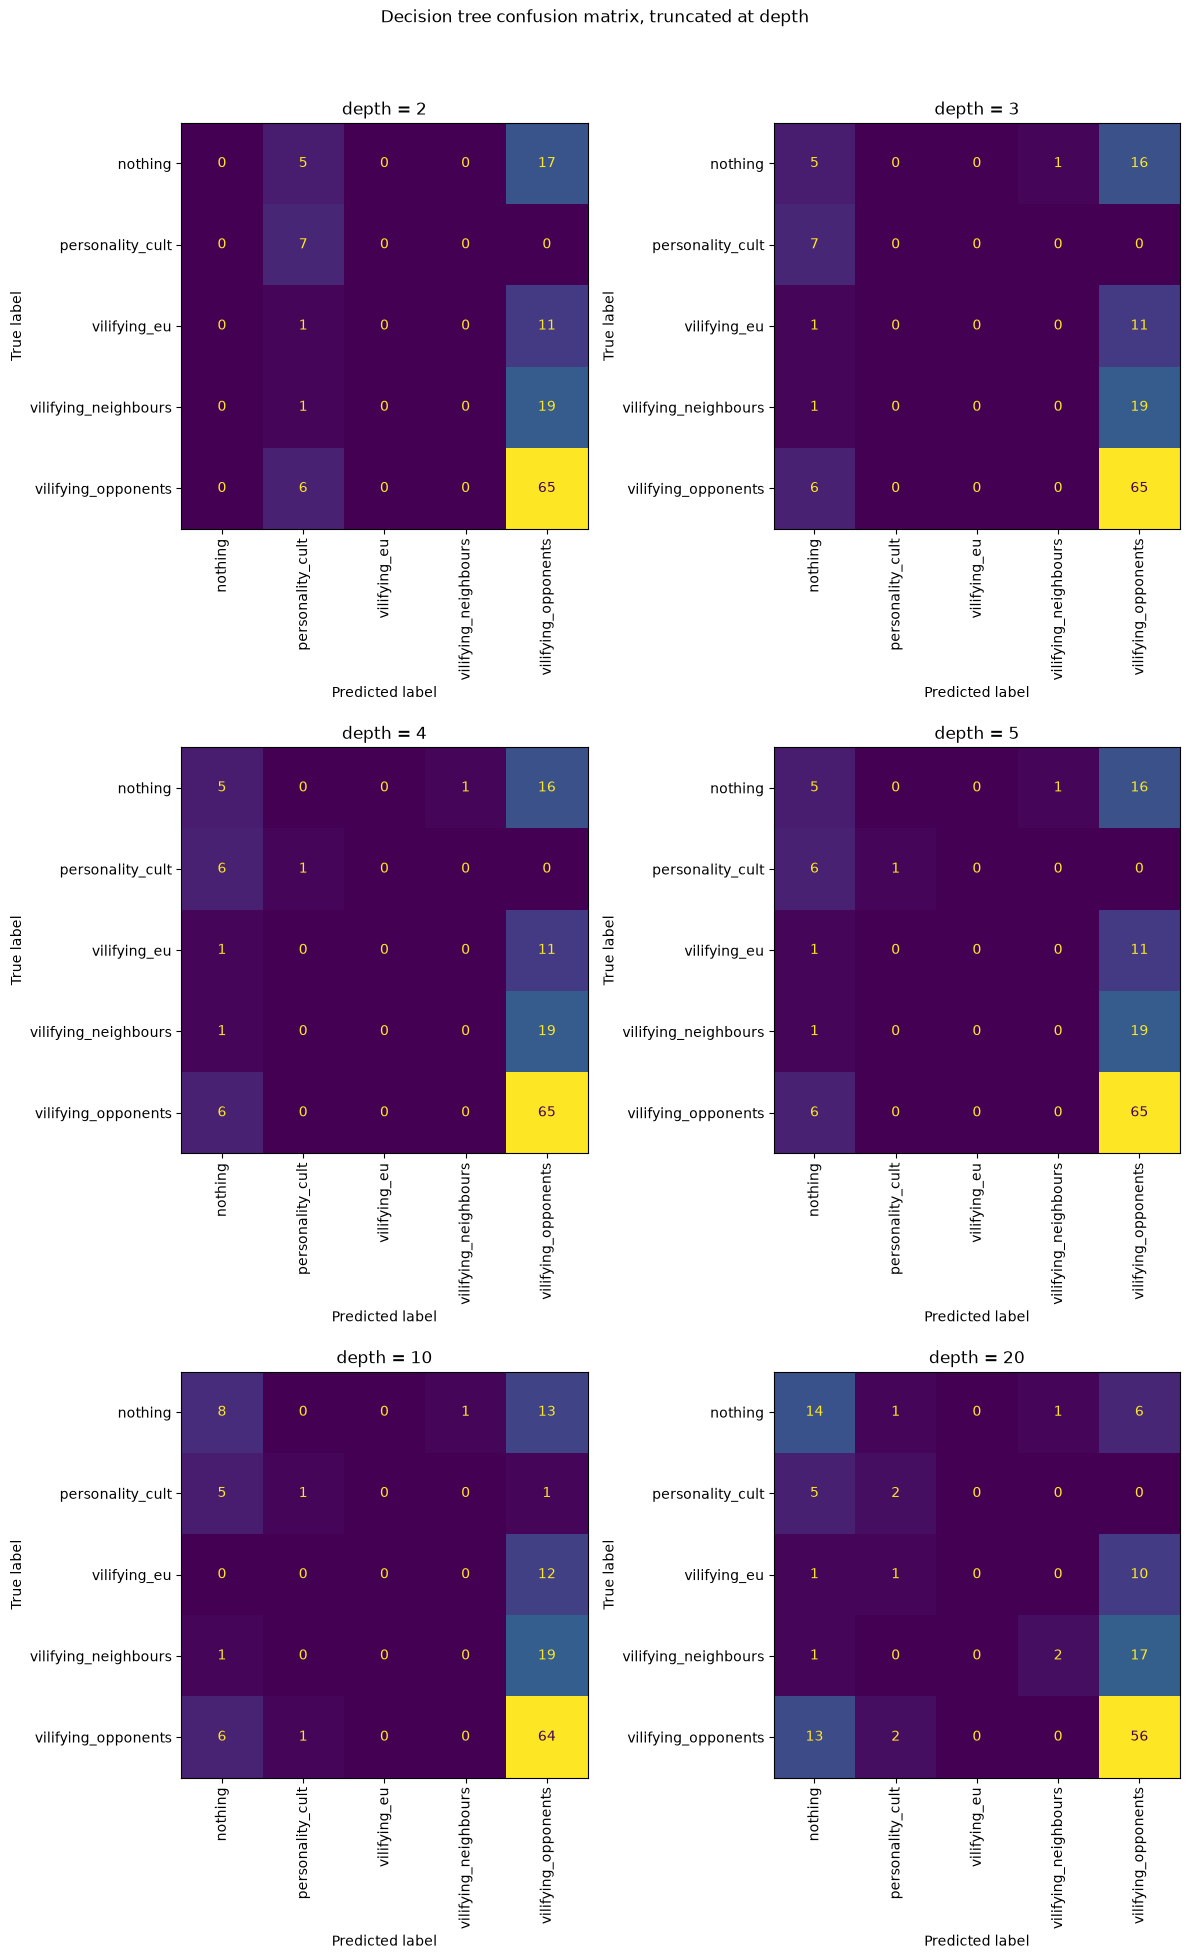

In [20]:
decision_tree_depths = [2, 3, 4, 5, 10, 20]

X_train = vectorizer.transform(train["headline"])
X_test = vectorizer.transform(test["headline"])

fig = plt.figure(figsize=(1200, 2000, "px"))

for i, depth in enumerate(decision_tree_depths):
    depth_tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    depth_tree.fit(X_train, train["label"])
    depth_predictions = depth_tree.predict(X_test)

    ax = plt.subplot(321 + i)
    ConfusionMatrixDisplay.from_predictions(
        test["label"],
        depth_predictions,
        ax=ax,
        labels=labels,
        xticks_rotation="vertical",
        colorbar=False,
    )
    ax.set_title(f"depth = {depth}")

fig.suptitle("Decision tree confusion matrix, truncated at depth")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

Best settings: {'decisiontreeclassifier__class_weight': {'nothing': 4, 'personality_cult': 1.0, 'vilifying_eu': 1.0, 'vilifying_neighbours': 1.0, 'vilifying_opponents': 1.0}, 'decisiontreeclassifier__max_depth': 3, 'decisiontreeclassifier__min_samples_leaf': 1}
CV nothing F1: 1.000
Test nothing precision: 0.189
Test nothing recall:    0.955
Test nothing examples:  22


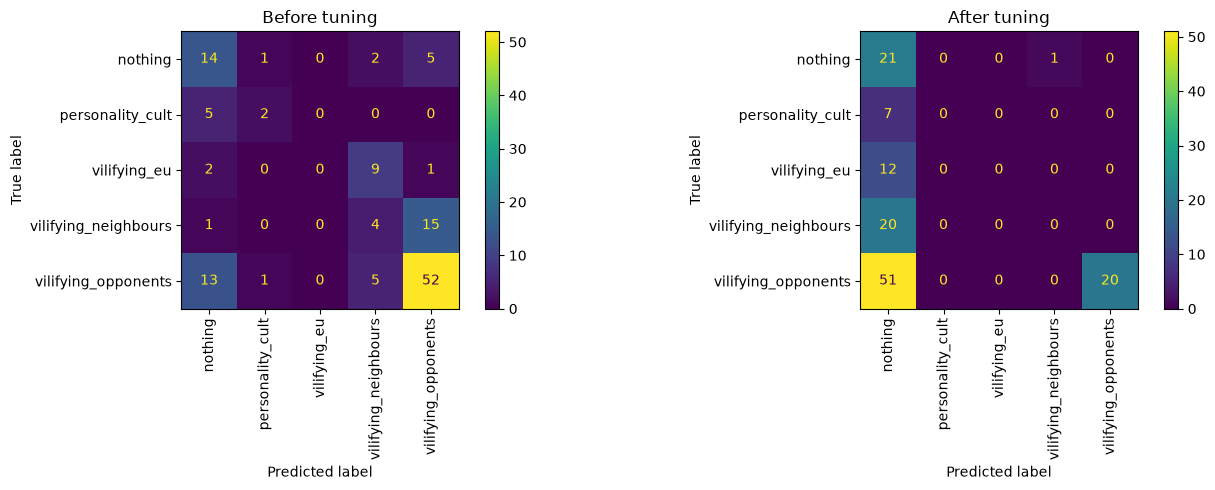

In [6]:
from sklearn.base import clone
from sklearn.metrics import f1_score, make_scorer, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, GroupKFold

target = "nothing"

target_class_weights = [
    {label: (weight if label == target else 1.0) for label in labels}
    for weight in [1, 2, 4, 8]
]

search = GridSearchCV(
    estimator=clone(classifier),
    param_grid={
        "decisiontreeclassifier__max_depth": [3, 5, 10, None],
        "decisiontreeclassifier__min_samples_leaf": [1, 2, 4, 8],
        "decisiontreeclassifier__class_weight": [
            None,
            "balanced",
            *target_class_weights,
        ],
    },
    scoring=make_scorer(
        recall_score,
        labels=[target],
        average="micro",
        zero_division=0,
    ),
    cv=GroupKFold(n_splits=3),
    refit=True,
    n_jobs=-1,
)

search.fit(train["headline"], train["label"], groups=train["group"])

tuned_model = search.best_estimator_
tuned_predictions = tuned_model.predict(test["headline"])

y_true = test["label"].eq(target)
y_pred = pd.Series(tuned_predictions, index=test.index).eq(target)

print("Best settings:", search.best_params_)
print(f"CV {target} F1: {search.best_score_:.3f}")
print(f"Test {target} precision: {precision_score(y_true, y_pred, zero_division=0):.3f}")
print(f"Test {target} recall:    {recall_score(y_true, y_pred, zero_division=0):.3f}")
print(f"Test {target} examples:  {y_true.sum()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    test["label"], predictions, labels=labels, xticks_rotation="vertical", ax=axes[0]
)
axes[0].set_title("Before tuning")

ConfusionMatrixDisplay.from_predictions(
    test["label"], tuned_predictions, labels=labels, xticks_rotation="vertical", ax=axes[1]
)
axes[1].set_title("After tuning")

plt.tight_layout()
plt.show()